<a href="https://colab.research.google.com/github/amolloelly-png/AI-for-Science-and-Engineering/blob/main/Week_6_assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Discovering Patterns in Data

# Clustering Petroleum Stations by Safety and Compliance Characteristics

## Objective
Use **unsupervised learning** to group petroleum stations with similar safety and compliance profiles.


## 1. Import libraries and load the dataset

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

DATA_PATH = "/content/kenya_petroleum_stations_safety_dataset-3.csv"
df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
display(df.head())
print("\\nMissing values in selected fields:")

Dataset shape: (200, 34)


,station_id,station_name,location,county_region,facility_type,year_established,num_dispensers,num_staff,pms_storage_capacity_litres,ago_storage_capacity_litres,...,oil_water_separator_status,spill_kit_status,calibration_status,days_since_last_calibration,last_inspection_date,previous_inspection_findings,non_compliance_severity,previous_incident,incident_year,historical_risk_classification
0,KE-PS-0001,Station 1,"Town Centre, Kiambu",Kiambu,Service Station,2021,2,9,20000,30000,...,Present & Functional,Expired Materials,Due Within 30 Days,321.0,2025-06-28,Lightning arrestor disconnected,Medium,Minor fuel spill (contained),2025.0,Medium
1,KE-PS-0002,Station 2,"Highway, Marsabit",Marsabit,Retail Filling Station,2015,4,21,80000,30000,...,Present & Functional,Available,Overdue,123.0,2025-06-23,Pump calibration overdue,NaN,Electrical short circuit,2021.0,Medium
2,KE-PS-0003,Station 3,"Highway, Trans Nzoia",Trans Nzoia,Retail Filling Station,2012,4,21,40000,30000,...,Present & Functional,Incomplete,Overdue,141.0,2025-05-29,Underground tank integrity concerns; Fire exti...,NaN,None recorded,NaN,Medium
3,KE-PS-0004,Station 4,"Town Centre, Kericho",Kericho,Urban Mini Station,2007,9,7,60000,20000,...,Present & Functional,NaN,Due Within 30 Days,226.0,2026-08-12,No major findings,Medium,None recorded,NaN,High
4,KE-PS-0005,Station 5,"Industrial Area, Mombasa",Mombasa,Service Station,2010,2,20,30000,30000,...,Present & Functional,Available,Up to Date,40.0,2026-06-30,Staff PPE non-compliance,Low,None recorded,NaN,Low


\nMissing values in selected fields:


## 2. Selecting features for clustering

The features below describe station size and safety/compliance conditions. Numeric features are scaled, and categorical features are one-hot encoded. Missing values are imputed inside the preprocessing pipeline.

We exclude station names/IDs, location labels, inspection dates and the existing risk/severity labels because they are identifiers, not suitable direct measures for this clustering objective. We also exclude `incident_year` because it is missing for stations without a recorded incident and is difficult to interpret as a general safety measure.

In [4]:
numeric_features = [
    "num_dispensers",
    "num_staff",
    "pms_storage_capacity_litres",
    "ago_storage_capacity_litres",
    "lpg_storage_capacity_kg",
    "lpg_cylinder_count",
    "num_fire_extinguishers",
    "num_sand_buckets",
    "num_fire_points",
    "days_since_last_calibration",
]

categorical_features = [
    "facility_type",
    "has_lpg",
    "lpg_compliance_status",
    "fire_extinguisher_condition",
    "emergency_shutdown_status",
    "leakage_observation",
    "earthing_compliance",
    "electrical_safety_status",
    "lightning_protection",
    "environmental_compliance",
    "oil_water_separator_status",
    "spill_kit_status",
    "calibration_status",
    "previous_incident",
]

selected_features = numeric_features + categorical_features
X = df[selected_features].copy()

print("Number of selected features:", len(selected_features))
display(X.head())
display(X.isna().sum().sort_values(ascending=False).to_frame("Missing values").head(10))

Number of selected features: 24


,num_dispensers,num_staff,pms_storage_capacity_litres,ago_storage_capacity_litres,lpg_storage_capacity_kg,lpg_cylinder_count,num_fire_extinguishers,num_sand_buckets,num_fire_points,days_since_last_calibration,...,emergency_shutdown_status,leakage_observation,earthing_compliance,electrical_safety_status,lightning_protection,environmental_compliance,oil_water_separator_status,spill_kit_status,calibration_status,previous_incident
0,2,9,20000,30000,0,0,9,7,2,321.0,...,Functional,Minor Seepage,Compliant,Compliant,Installed & Functional,Under Notice,Present & Functional,Expired Materials,Due Within 30 Days,Minor fuel spill (contained)
1,4,21,80000,30000,5000,62,4,1,2,123.0,...,Partial,None Observed,Compliant,Minor Defects,Not Installed,Minor Non-Compliance,Present & Functional,Available,Overdue,Electrical short circuit
2,4,21,40000,30000,1000,117,9,3,2,141.0,...,Partial,None Observed,Non-Compliant,Minor Defects,Installed - Needs Maintenance,Compliant,Present & Functional,Incomplete,Overdue,None recorded
3,9,7,60000,20000,5000,20,6,2,1,226.0,...,Functional,Active Leak - Contained,Non-Compliant,Minor Defects,Not Installed,Minor Non-Compliance,Present & Functional,NaN,Due Within 30 Days,None recorded
4,2,20,30000,30000,500,119,2,4,1,40.0,...,Functional,None Observed,Compliant,Compliant,Not Installed,Compliant,Present & Functional,Available,Up to Date,None recorded


,Missing values
lpg_compliance_status,59
spill_kit_status,26
days_since_last_calibration,10
num_dispensers,0
lpg_storage_capacity_kg,0
num_staff,0
pms_storage_capacity_litres,0
ago_storage_capacity_litres,0
num_sand_buckets,0
num_fire_extinguishers,0


## 3. Preparing the features

K-Means relies on distances. Standardising numerical variables prevents large capacity values from dominating smaller numeric fields.

In [5]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features),
])

X_prepared = preprocessor.fit_transform(X)
print("Prepared feature matrix shape:", X_prepared.shape)


Prepared feature matrix shape: (200, 71)


## 4. Explore different numbers of clusters

We compare values of *k* from 2 to 8 using:
- **Inertia (elbow method):** lower is better, but the rate of improvement may slow as extra clusters are added.
- **Silhouette score:** ranges approximately from -1 to 1; higher values generally indicate better separation and cohesion.

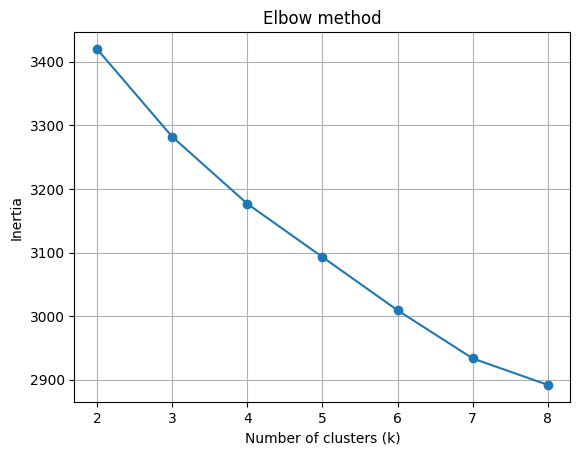

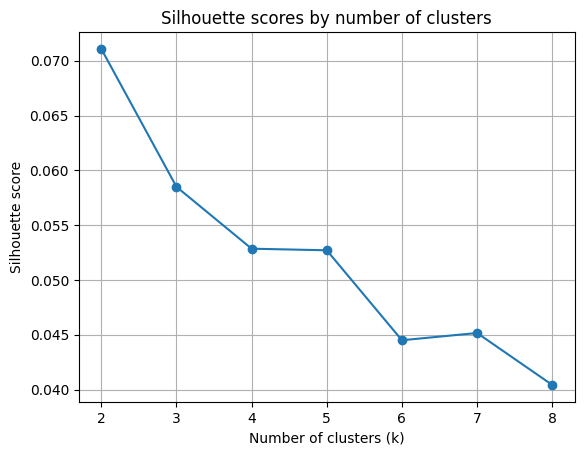

,k,inertia,silhouette_score
0,2,3420.035432,0.071076
1,3,3282.167153,0.058497
2,4,3176.708011,0.052851
3,5,3092.944220,0.052706
4,6,3009.210594,0.044500
5,7,2933.480115,0.045162
6,8,2891.868244,0.040424


Highest silhouette score occurs at k = 2


In [6]:
k_values = range(2, 9)
inertias = []
silhouette_scores = []

for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_prepared)
    inertias.append(model.inertia_)
    silhouette_scores.append(silhouette_score(X_prepared, labels))

fig, ax = plt.subplots()
ax.plot(list(k_values), inertias, marker="o")
ax.set_xlabel("Number of clusters (k)")
ax.set_ylabel("Inertia")
ax.set_title("Elbow method")
ax.set_xticks(list(k_values))
ax.grid(True)
plt.show()

fig, ax = plt.subplots()
ax.plot(list(k_values), silhouette_scores, marker="o")
ax.set_xlabel("Number of clusters (k)")
ax.set_ylabel("Silhouette score")
ax.set_title("Silhouette scores by number of clusters")
ax.set_xticks(list(k_values))
ax.grid(True)
plt.show()

scores = pd.DataFrame({
    "k": list(k_values),
    "inertia": inertias,
    "silhouette_score": silhouette_scores,
})
display(scores)
print("Highest silhouette score occurs at k =", scores.loc[scores["silhouette_score"].idxmax(), "k"])

## 5. Fit the selected clustering model

The code below selects the *k* with the highest silhouette score as a reproducible starting point.

In [8]:
best_k = int(scores.loc[scores["silhouette_score"].idxmax(), "k"])
kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=10)
df["cluster"] = kmeans.fit_predict(X_prepared)

print(f"Selected number of clusters: {best_k}")
display(df["cluster"].value_counts().sort_index().rename("station_count").to_frame())

Selected number of clusters: 2


,station_count
cluster,
0,134
1,66


## 6. Visualise the clusters

For a simple two-dimensional visualisation, Principal Component Analysis (PCA) compresses the prepared features into two components. Points close together have more similar profiles in the transformed feature space. The plot is a projection, so some differences in the original high-dimensional data may not be visible.

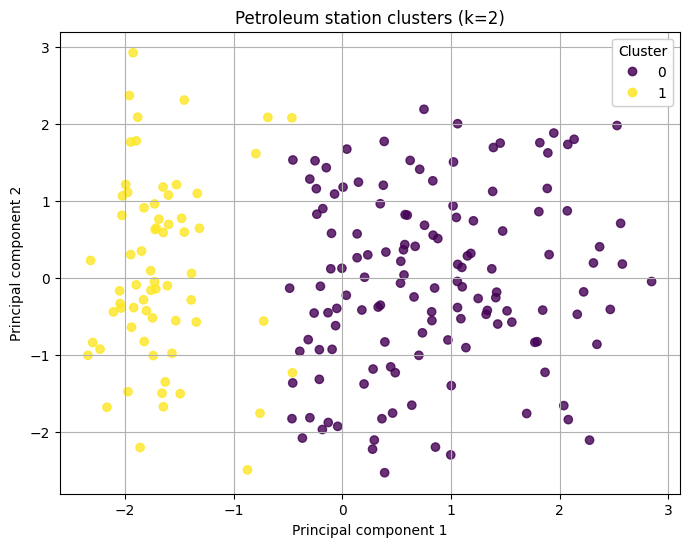

Variance explained by the two displayed components: 17.6 %


In [9]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=42)
X_2d = pca.fit_transform(X_prepared)

fig, ax = plt.subplots(figsize=(8, 6))
scatter = ax.scatter(X_2d[:, 0], X_2d[:, 1], c=df["cluster"], alpha=0.8)
ax.set_xlabel("Principal component 1")
ax.set_ylabel("Principal component 2")
ax.set_title(f"Petroleum station clusters (k={best_k})")
ax.grid(True)
legend = ax.legend(*scatter.legend_elements(), title="Cluster")
ax.add_artist(legend)
plt.show()

print("Variance explained by the two displayed components:",
      round(pca.explained_variance_ratio_.sum() * 100, 1), "%")


## 7. Describe the groups

Compare the clusters using safety indicators and operational features. The following tables show cluster sizes, selected numeric averages and the most common category for each selected categorical field.

In [11]:
cluster_sizes = df["cluster"].value_counts().sort_index().rename("station_count")
display(cluster_sizes.to_frame())

numeric_profile = df.groupby("cluster")[numeric_features].mean().round(1)
display(numeric_profile)

def most_common(series):
    modes = series.mode(dropna=True)
    return modes.iloc[0] if not modes.empty else "Unknown"

categorical_profile = df.groupby("cluster")[categorical_features].agg(most_common).T
display(categorical_profile)


,station_count
cluster,
0,134
1,66


,num_dispensers,num_staff,pms_storage_capacity_litres,ago_storage_capacity_litres,lpg_storage_capacity_kg,lpg_cylinder_count,num_fire_extinguishers,num_sand_buckets,num_fire_points,days_since_last_calibration
cluster,,,,,,,,,,
0,6.9,13.7,43507.5,46417.9,1940.3,112.5,6.8,3.9,2.5,201.8
1,6.2,14.6,46060.6,55000.0,68.2,4.2,6.9,4.1,2.3,216.1


cluster,0,1
facility_type,Retail Filling Station,Retail Filling Station
has_lpg,True,False
lpg_compliance_status,Minor Issues,Under Review
fire_extinguisher_condition,Serviceable,Serviceable
emergency_shutdown_status,Functional,Functional
leakage_observation,None Observed,None Observed
earthing_compliance,Compliant,Compliant
electrical_safety_status,Compliant,Compliant
lightning_protection,Installed & Functional,Installed & Functional
environmental_compliance,Compliant,Compliant


## 8. Markdown discussion: interpretation and limitations

1. Cluster 0: Safety, Compliance and Operational Characteristics
Cluster 0 contains 134 petroleum retail stations, representing 67% of the 200 stations in the dataset. All stations in this cluster are classified as retail filling stations. The average number of dispensers is 6.9, with approximately 13.7 staff members per station. The average PMS and AGO storage capacities are 43,507.5 litres and 46,417.9 litres, respectively.

Most stations in this cluster have LPG facilities, with an average LPG storage capacity of 1,940.3 kg and approximately 112.5 LPG cylinders. The average number of fire extinguishers is 6.8, while the average number of sand buckets and fire points is 3.9 and 2.5, respectively.

Regarding safety and compliance, the cluster profile indicates that fire extinguishers are serviceable, emergency shutdown systems are functional, and no leakages have been observed. Earthing and electrical systems are compliant, lightning protection is installed and functional, and environmental controls are compliant. Oil-water separators are present and functional, spill kits are available, and calibration is recorded as up to date. The LPG compliance status is generally described as having minor issues.

However, the average of 201.8 days since the last calibration suggests that the underlying calibration records should be verified, even though the categorical calibration status is reported as up to date. This discrepancy may reflect differences in the dataset's recording methods.

Overall, Cluster 0 represents a relatively large group of stations with LPG facilities and generally positive recorded safety and compliance conditions.

2. Other Cluster: Comparison with Cluster 0
Cluster 1 contains 66 stations, representing 33% of the dataset. Like Cluster 0, all stations are classified as retail filling stations.

The average number of dispensers is 6.2, while the average number of staff is 14.6. The average PMS storage capacity is 46,060.6 litres, and the average AGO storage capacity is 55,000 litres. Unlike Cluster 0, stations in Cluster 1 do not have LPG facilities according to the cluster profile.

The two clusters show similar recorded safety and compliance conditions:
- Fire extinguishers: Both clusters have serviceable fire extinguishers. The average counts are 6.8 and 6.9 for Clusters 0 and 1, respectively.
- Emergency shutdown: Both clusters have functional emergency shutdown systems.
- Leakage observations: Neither cluster has recorded observed leakages.
- Earthing and electrical safety: Both clusters are compliant.
- Lightning protection: Both clusters have installed and functional lightning protection.
- Environmental compliance: Both clusters are compliant, with oil-water separators present and functional.
- Calibration: Both clusters report calibration as up to date, although the average days since the last calibration are 201.8 for Cluster 0 and 216.1 for Cluster 1.
Both clusters also report available spill kits and no recorded previous incidents.

The most noticeable difference between the clusters is therefore the presence or absence of LPG facilities and their associated storage capacity and cylinder counts. Cluster 1 also has a higher average AGO storage capacity and a slightly higher average number of staff.

3. Possible Meaning of the Clusters
The clustering results suggest that the stations have been grouped primarily according to differences in their operational characteristics, particularly LPG facilities and storage-related variables.

Cluster 0 may represent retail filling stations that provide LPG services alongside conventional petroleum products. These stations have substantial LPG storage capacity and cylinder counts, meaning their inspections may need to consider both petroleum-related requirements and LPG-specific safety controls.

Cluster 1 may represent retail filling stations that handle conventional petroleum products without LPG facilities. Their higher average AGO storage capacity may be relevant when planning inspections of petroleum storage and handling systems.

Both clusters show generally positive recorded safety conditions. Consequently, the results do not provide sufficient evidence to classify one cluster as safer or riskier than the other.

The clusters could help organise inspections according to facility characteristics and the types of safety controls that need verification.
